In [1]:
import torch

pt_path = '/mnt/central_nas/rcc_volume/RCC/HE/CLAM/TME_archetypes/features/pt_files/ZTMA20.1_X1Y2.pt'

features = torch.load(pt_path)  # Tensor [N_patches, feature_dim]

print(features.shape)


torch.Size([96, 1024])


In [12]:
import os
import torch

pt_dir = "/mnt/central_nas/rcc_volume/RCC/HE/CLAM/TME_archetypes/features/pt_files/"

all_features = {}

for fname in os.listdir(pt_dir):
    if fname.endswith(".pt"):
        slide_id = fname.replace(".pt", "")
        features = torch.load(os.path.join(pt_dir, fname))
        all_features[slide_id] = features  # [N_patches, D]

print(len(all_features), "slides loaded")


796 slides loaded


In [13]:
import torch
import numpy as np

# collect features and bookkeeping
all_patches = []
slide_patch_map = []  # (slide_id, patch_idx)

for slide_id, feats in all_features.items():
    feats = feats.cpu()
    all_patches.append(feats)
    slide_patch_map.extend([(slide_id, i) for i in range(feats.shape[0])])

X = torch.cat(all_patches, dim=0).numpy()  # [N_total_patches, D]

print("Total patches:", X.shape[0])
print("Feature dim:", X.shape[1])


Total patches: 90942
Feature dim: 1024


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [15]:
from sklearn.decomposition import PCA

n_components = 50  # common choice
pca = PCA(n_components=n_components, random_state=0)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:",
      pca.explained_variance_ratio_.sum())


Explained variance ratio: 0.6586635


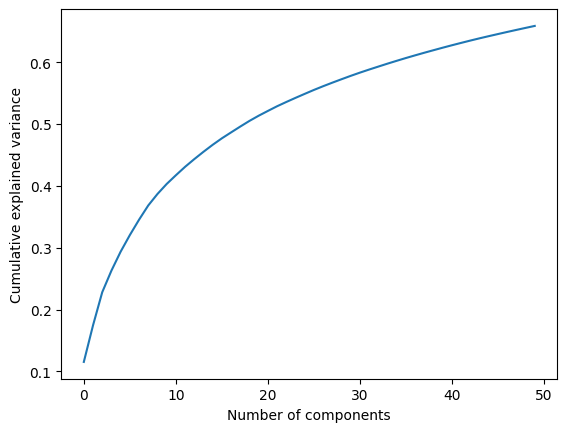

In [16]:
import matplotlib.pyplot as plt

plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.show()


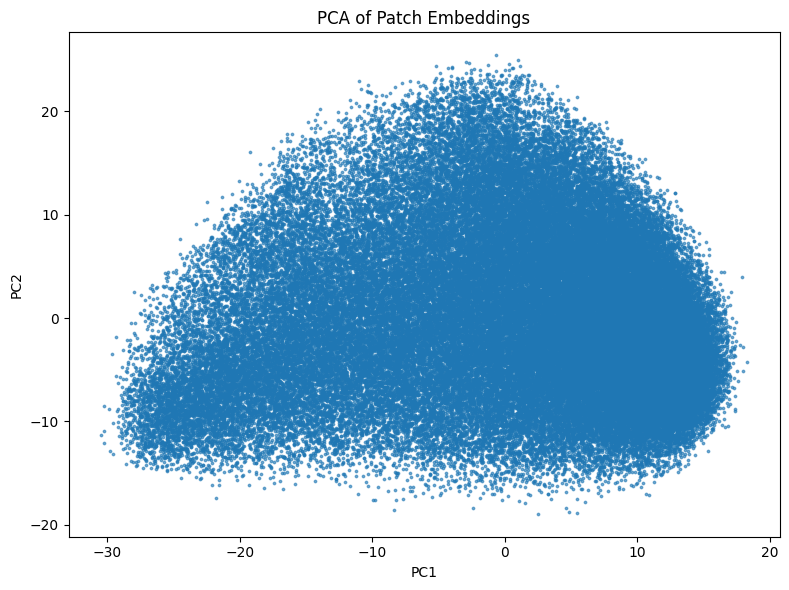

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    s=3,
    alpha=0.6
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Patch Embeddings")
plt.tight_layout()
plt.show()


In [18]:
import umap
import matplotlib.pyplot as plt

umap_model = umap.UMAP(
    n_neighbors=15,      # local vs global structure
    min_dist=0.1,        # cluster tightness
    n_components=2,
    metric="euclidean",
    random_state=42
)

X_umap = umap_model.fit_transform(X_pca)

print(X_umap.shape)  # (N_patches, 2)


/home/ubuntu/miniconda3/envs/clam_latest/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/ubuntu/miniconda3/envs/clam_latest/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(90942, 2)


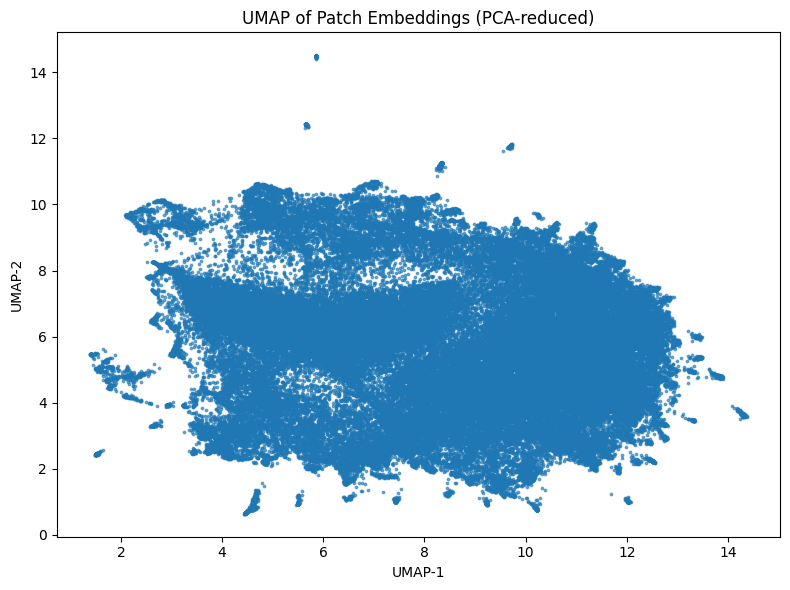

In [19]:
plt.figure(figsize=(8, 6))
plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    s=3,
    alpha=0.6
)
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.title("UMAP of Patch Embeddings (PCA-reduced)")
plt.tight_layout()
plt.show()

In [26]:
from sklearn.cluster import KMeans

n_clusters = 9  # choose based on biology / elbow / silhouette

kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=0,
    n_init=20
)

cluster_labels = kmeans.fit_predict(X_pca)


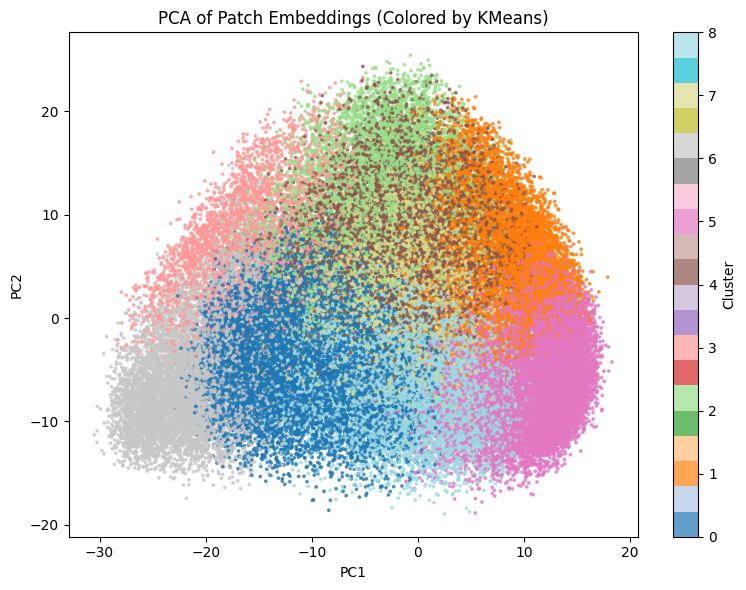

In [27]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap="tab20",
    s=3,
    alpha=0.7
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Patch Embeddings (Colored by KMeans)")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()



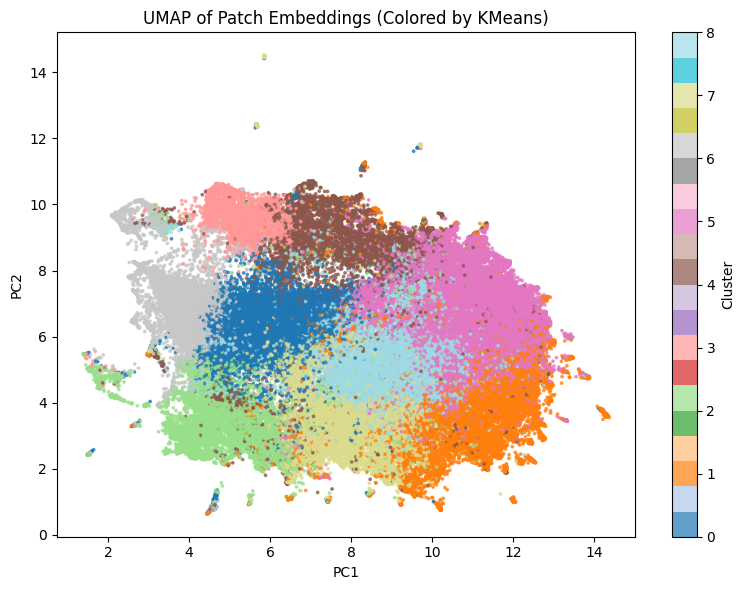

In [28]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=cluster_labels,
    cmap="tab20",
    s=3,
    alpha=0.7
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("UMAP of Patch Embeddings (Colored by KMeans)")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

In [20]:
X_eval = X_pca   # shape: (N_patches, n_components)

In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np

Ks = range(3, 20)
sil_scores = []

# subsample if large
max_samples = 10000
if X_eval.shape[0] > max_samples:
    idx = np.random.choice(X_eval.shape[0], max_samples, replace=False)
    X_sub = X_eval[idx]
else:
    X_sub = X_eval

for k in Ks:
    kmeans = KMeans(n_clusters=k, random_state=0, n_init=20)
    labels = kmeans.fit_predict(X_sub)
    score = silhouette_score(X_sub, labels)
    sil_scores.append(score)


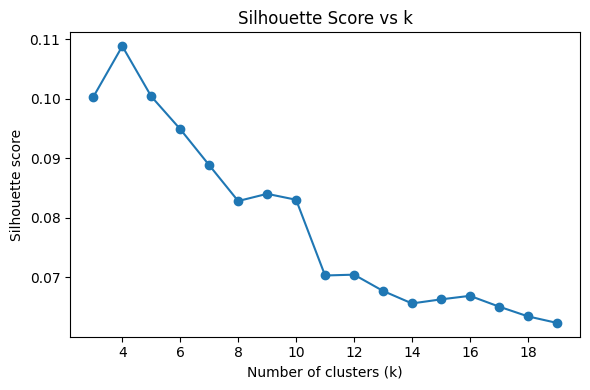

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(Ks, sil_scores, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score vs k")
plt.tight_layout()
plt.show()